# 08 — Learning to rank avec XGBoost

**Objectif** : remplacer les poids fixes de l'hybride par un modèle supervisé qui apprend lui-même
à classer les films, à partir des scores de tous les modèles et de variables que l'hybride ne voit
pas (popularité, âge du film, profil de l'utilisateur, affinité de genres).

Architecture en deux étages, comme dans un système en production :

1. **génération de candidats** : l'hybride du Sprint 4 propose 100 films par utilisateur ;
2. **ranking** : `XGBRanker` les réordonne.

Ce notebook charge les résultats et le modèle de `python scripts/train_ranking.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from recsys.analysis import hybrid_report, model_report, ranking_report
from recsys.config import load_config
from recsys.experiments import collaborative, content, hybrid, ranking
from recsys.experiments.runner import build_folds, load_ratings
from recsys.features.ranking import RankingFeatureBuilder, graded_labels
from recsys.models.collaborative import ImplicitALS, ItemKNN
from recsys.models.content_based import ContentBasedRecommender
from recsys.models.hybrid import HybridRecommender
from recsys.models.ranking import RankingRecommender

%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 70)

config = load_config()
reports, artifacts = config.paths.reports_dir, config.paths.artifacts_dir
results = model_report.load_results(reports, ranking.RESULTS_FILE)
movies = pd.read_parquet(config.paths.processed_dir / "movies.parquet")


def show(fig):
    display(fig)
    plt.close(fig)

## 1. Éviter les fuites : qui voit quoi, et quand

| | Modèles de base entraînés jusqu'à | Labels pris dans |
|---|---|---|
| Entraînement du ranker | 25 juin 2016 | 25 juin 2016 → 4 janvier 2018 |
| Test du ranker | 4 janvier 2018 | 4 janvier 2018 → 21 novembre 2019 |

- Les variables d'une ligne sont calculées **uniquement** avec ce qui précède la période de ses
  labels : c'est ce dont on disposerait au moment de recommander.
- Les hyperparamètres sont choisis sur 20 % des utilisateurs d'entraînement du ranker, mis de
  côté. Le test ne sert qu'à la mesure finale.
- Si le ranker était entraîné sur les mêmes notes que ses modèles de base, leurs scores seraient
  artificiellement bons sur ces lignes et il apprendrait à leur faire trop confiance.

In [2]:
pd.Series(results["dataset"]).to_frame("jeu d'entraînement du ranker")

,jeu d'entraînement du ranker
n_candidates,100
train_users,4005
dev_users,1001
train_rows,400500
label_counts,"{'liked': 27659, 'unknown': 357005, 'disliked': 15836}"
users_without_positive_candidate,581
candidate_recall_dev,0.3221
feature_seconds,81.0475
candidate_recall_test_sample,0.3025


## 2. Labels : une absence de note n'est pas un avis négatif

Parmi les 100 candidats d'un utilisateur, la plupart n'ont jamais été notés. Les traiter comme
des échecs reviendrait à affirmer qu'il ne les aurait pas aimés. Deux schémas sont comparés :

- **gradué** : 2 = aimé (note ≥ 4), 1 = non noté (inconnu), 0 = noté sous 4 (rejet explicite) ;
- **binaire** : 1 = aimé, 0 = tout le reste (référence).

In [3]:
display(ranking_report.dataset_table(results))
validation = model_report.results_frame(results["validation"])
print("Référence, ordre de l'hybride sans ranker :", results["dev_reference"])
validation[["params", "ndcg@10", "recall@10", "fit_seconds"]]

,label,lignes,part
0,2 — aimé (note ≥ seuil),27659,6.91%
1,1 — non noté (inconnu),357005,89.14%
2,0 — noté sous le seuil (rejet),15836,3.95%


Référence, ordre de l'hybride sans ranker : {'ndcg@10': 0.18029100134999107, 'recall@10': 0.0774199983093173, 'coverage@10': 0.1025035765379113}


,params,ndcg@10,recall@10,fit_seconds
0,"labels=graded, max_depth=4, learning_rate=0.05, best_iteration=172",0.2248,0.1044,31.8111
1,"labels=graded, max_depth=6, learning_rate=0.05, best_iteration=251",0.2265,0.1038,72.3000
2,"labels=graded, max_depth=6, learning_rate=0.1, best_iteration=132",0.2262,0.1032,51.4837
3,"labels=binary, max_depth=4, learning_rate=0.05, best_iteration=128",0.2250,0.1047,26.8944
4,"labels=binary, max_depth=6, learning_rate=0.05, best_iteration=140",0.2281,0.1050,33.8419
5,"labels=binary, max_depth=6, learning_rate=0.1, best_iteration=139",0.2272,0.1053,33.8248


In [4]:
print("Configuration retenue sur le jeu de dev :", results["best"])

Configuration retenue sur le jeu de dev : {'params': {'labels': 'binary', 'max_depth': 6, 'learning_rate': 0.05, 'best_iteration': 140}, 'dev_ndcg@10': 0.22812121740867258}


## 3. Les variables

Chaque ligne décrit un couple (utilisateur, film candidat).

In [5]:
pd.DataFrame({"variable": results["feature_names"],
              "description": [ranking_report.feature_label(n) for n in results["feature_names"]]})

,variable,description
0,score_als_implicit,score ALS implicite
1,score_item_knn,score Item-kNN
2,score_tfidf,score Contenu TF-IDF
3,score_embeddings,score Contenu embeddings
4,log_rank_als_implicit,rang ALS implicite
5,log_rank_item_knn,rang Item-kNN
6,log_rank_tfidf,rang Contenu TF-IDF
7,log_rank_embeddings,rang Contenu embeddings
8,score_hybrid,score de l'hybride
9,item_log_popularity,popularité du film


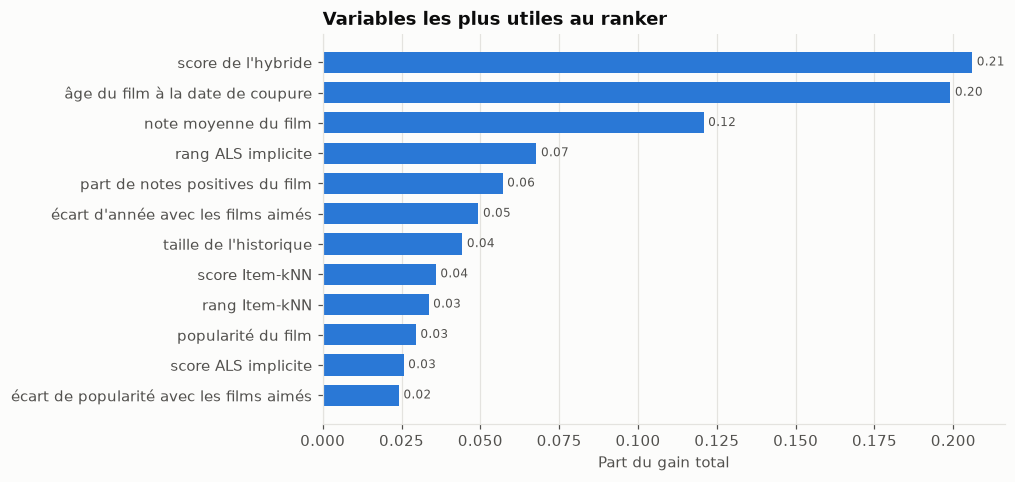

,variable,nom technique,part du gain
0,score de l'hybride,score_hybrid,0.2060
1,âge du film à la date de coupure,item_age,0.1991
2,note moyenne du film,item_mean_rating,0.1208
3,rang ALS implicite,log_rank_als_implicit,0.0678
4,part de notes positives du film,item_liked_share,0.0571
5,écart d'année avec les films aimés,year_gap,0.0494
6,taille de l'historique,user_log_history,0.0443
7,score Item-kNN,score_item_knn,0.0359
8,rang Item-kNN,log_rank_item_knn,0.0336
9,popularité du film,item_log_popularity,0.0295


In [6]:
show(ranking_report.plot_importance(results))
ranking_report.importance_table(results)

## 4. Résultats sur le test

Même protocole, mêmes utilisateurs et même catalogue que tous les modèles précédents. Deux
ablations isolent ce qui fait la différence :

- **sans variables de récence** : on retire l'âge du film et l'écart d'année ;
- **scores des modèles seuls** : le ranker ne voit que ce que voit l'hybride.

In [7]:
best_hybrid = model_report.load_results(reports, hybrid.RESULTS_FILE)["best"]["model"]
rows = [r for r in model_report.load_results(reports, collaborative.RESULTS_FILE)["test"]
        if r["model"] in ("popularity", "als_implicit")]
rows += [r for r in model_report.load_results(reports, hybrid.RESULTS_FILE)["test"]
         if r["model"] == best_hybrid]
test = model_report.results_frame(rows + results["test"])
for k in results["protocol"]["ks"]:
    print(f"Top-{k}")
    display(model_report.ranking_table(test, k).set_index("modèle"))

Top-5


,precision@5,recall@5,f1@5,map@5,ndcg@5,coverage@5
modèle,,,,,,
Popularité,0.0781,0.0207,0.0248,0.0545,0.0861,0.0131
ALS implicite,0.1336,0.0345,0.0429,0.0953,0.1446,0.1010
Hybride agrégation de rangs (RRF),0.1517,0.0400,0.0497,0.1108,0.1630,0.1181
Ranking XGBoost,0.2022,0.0677,0.0774,0.1583,0.2270,0.0850
Ranking XGBoost (sans variables de récence),0.1732,0.0503,0.0605,0.1289,0.1878,0.1065
Ranking XGBoost (scores des modèles seuls),0.1393,0.0366,0.0447,0.0986,0.1484,0.1180


Top-10


,precision@10,recall@10,f1@10,map@10,ndcg@10,coverage@10
modèle,,,,,,
Popularité,0.0654,0.0319,0.0310,0.0406,0.0786,0.0188
ALS implicite,0.1202,0.0597,0.0595,0.0747,0.1381,0.1258
Hybride agrégation de rangs (RRF),0.1313,0.0674,0.0664,0.0855,0.1527,0.1575
Ranking XGBoost,0.1661,0.1014,0.0926,0.1221,0.2079,0.1202
Ranking XGBoost (sans variables de récence),0.1493,0.0852,0.0800,0.1007,0.1772,0.1396
Ranking XGBoost (scores des modèles seuls),0.1261,0.0641,0.0630,0.0784,0.1434,0.1492


Top-20


,precision@20,recall@20,f1@20,map@20,ndcg@20,coverage@20
modèle,,,,,,
Popularité,0.0564,0.0517,0.0383,0.0326,0.0766,0.0272
ALS implicite,0.1020,0.0964,0.0727,0.0610,0.1349,0.1531
Hybride agrégation de rangs (RRF),0.1116,0.1131,0.0817,0.0702,0.1506,0.2148
Ranking XGBoost,0.1327,0.1494,0.1020,0.1006,0.1992,0.1661
Ranking XGBoost (sans variables de récence),0.1233,0.1356,0.0935,0.0830,0.1734,0.1850
Ranking XGBoost (scores des modèles seuls),0.1093,0.1080,0.0791,0.0655,0.1434,0.1860


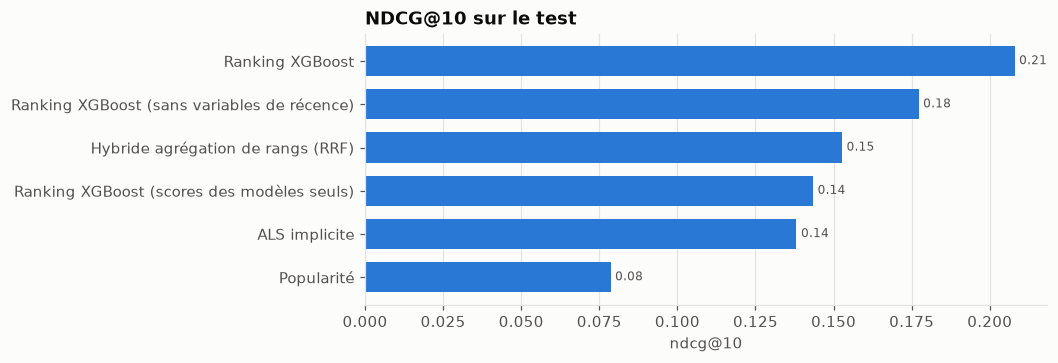

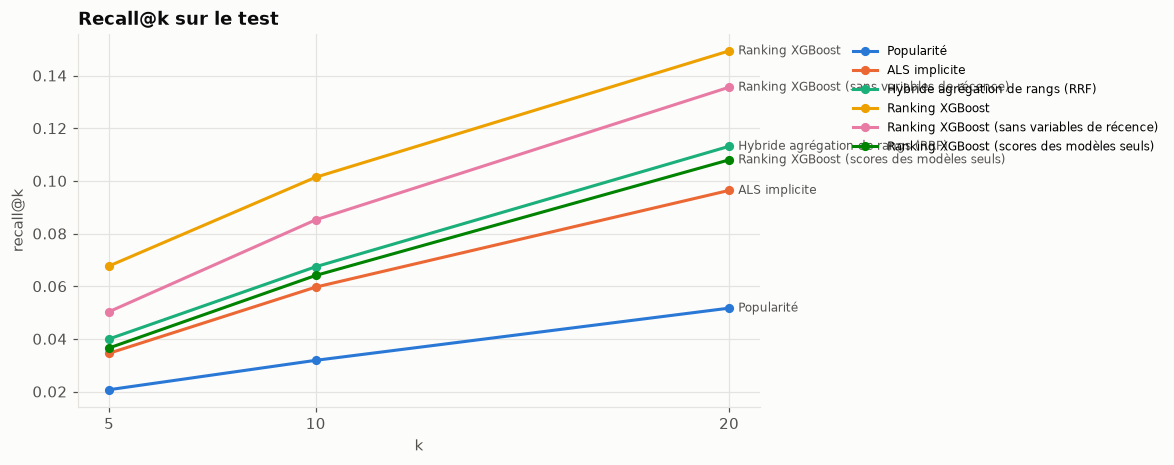

,hyperparamètres retenus,entraînement (s),ms / utilisateur,popularité moyenne du top-10
modèle,,,,
Popularité,relevance_threshold=4.0,0.2241,0.3387,"49,957.1268"
ALS implicite,"factors=64, reg=0.01, alpha=10, iterations=15, relevance_threshold...",111.5858,0.7941,"20,408.3544"
Hybride agrégation de rangs (RRF),"strategy=rrf, weights=als_implicit 0.50 + item_knn 0.25 + tfidf 0.25",0.0000,4.0017,"19,276.6391"
Ranking XGBoost,"max_depth=6, learning_rate=0.05, n_estimators=141, subsample=0.8, ...",31.1650,21.3562,"17,123.7887"
Ranking XGBoost (sans variables de récence),"max_depth=6, learning_rate=0.05, n_estimators=141, subsample=0.8, ...",34.7034,21.0123,"18,566.4604"
Ranking XGBoost (scores des modèles seuls),"max_depth=6, learning_rate=0.05, n_estimators=141, subsample=0.8, ...",18.8228,19.7411,"17,392.0030"


In [8]:
show(model_report.plot_metric(test, "ndcg@10", "NDCG@10 sur le test"))
show(model_report.plot_metric_by_k(test, "recall", results["protocol"]["ks"], "Recall@k sur le test"))
model_report.cost_table(test).set_index("modèle")

## 5. Le ranker en action

On recharge les composants, l'hybride et le ranker, puis on compare leur top-10 pour
l'utilisateur suivi depuis le notebook 04.

In [9]:
components = {
    "als_implicit": ImplicitALS.load(artifacts / collaborative.ARTIFACT_DIR / "als_implicit.pkl"),
    "item_knn": ItemKNN.load(artifacts / collaborative.ARTIFACT_DIR / "item_knn.pkl"),
    "tfidf": ContentBasedRecommender.load(artifacts / content.ARTIFACT_DIR / "tfidf.pkl"),
    "embeddings": ContentBasedRecommender.load(artifacts / content.ARTIFACT_DIR / "embeddings.pkl"),
}
hybrid_model = HybridRecommender.from_spec(artifacts / hybrid.ARTIFACT_DIR / hybrid.BEST_FILE, components)
fold = build_folds(load_ratings(config), config)["test"]
matrix = hybrid_model.matrix
builder = RankingFeatureBuilder(
    hybrid_model, components, movies, config.ranking.n_candidates,
    config.evaluation.relevance_threshold,
    reference_year=fold.train_end.year + (fold.train_end.dayofyear - 1) / 365.25,
).fit(matrix)
ranker = RankingRecommender.from_artifacts(artifacts / ranking.ARTIFACT_DIR / ranking.MODEL_FILE, builder)
titles = movies.set_index("movieId").loc[matrix.item_ids, "title"].to_numpy()
print(ranker.name, ranker.params)

C:\Users\DELL\AppData\Local\Temp\ipykernel_17648\3732998249.py:13: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  reference_year=fold.train_end.year + (fold.train_end.dayofyear - 1) / 365.25,


xgb_ranker {'max_depth': None, 'learning_rate': None, 'n_estimators': None, 'subsample': None, 'colsample_bytree': None, 'best_iteration': None, 'n_candidates': 100, 'n_features': 19}


In [10]:
history_size = np.diff(matrix.ratings.indptr)
relevant = fold.relevant.groupby("user_idx")["item_idx"].apply(set)
user = [u for u in fold.eval_users if 60 <= history_size[u] <= 150 and len(relevant[u]) >= 8][0]


def top10(model):
    items = model.recommend(np.array([user]), k=10)[0][0]
    return [f"{'✔ ' if i in relevant[user] else '   '}{titles[i]}" for i in items]


print(f"Utilisateur {matrix.user_ids[user]} — ✔ = film réellement aimé après la coupure")
pd.DataFrame({"Hybride": top10(hybrid_model), "Ranking XGBoost": top10(ranker)})

Utilisateur 294 — ✔ = film réellement aimé après la coupure


,Hybride,Ranking XGBoost
0,Apocalypse Now (1979),2001: A Space Odyssey (1968)
1,2001: A Space Odyssey (1968),Requiem for a Dream (2000)
2,"Silence of the Lambs, The (1991)",Apocalypse Now (1979)
3,Reservoir Dogs (1992),Psycho (1960)
4,Requiem for a Dream (2000),Eternal Sunshine of the Spotless Mind (2004)
5,Psycho (1960),✔ City of God (Cidade de Deus) (2002)
6,✔ City of God (Cidade de Deus) (2002),Reservoir Dogs (1992)
7,Eternal Sunshine of the Spotless Mind (2004),"Silence of the Lambs, The (1991)"
8,Blue Velvet (1986),Inception (2010)
9,Blade Runner (1982),Fargo (1996)


### Pourquoi ce film ? Les variables d'un candidat

In [11]:
batch = builder.build(np.array([user]))
scores = ranker.model.predict(batch.flat_features)
order = np.argsort(-scores)[:5]
frame = pd.DataFrame(batch.flat_features[order], columns=builder.feature_names)
frame.insert(0, "film", titles[batch.items[0][order]])
frame.insert(1, "score ranker", scores[order])
frame.insert(2, "rang hybride", order + 1)
frame[["film", "score ranker", "rang hybride", "score_hybrid", "item_age", "item_mean_rating",
       "item_log_popularity", "genre_affinity", "year_gap"]]

,film,score ranker,rang hybride,score_hybrid,item_age,item_mean_rating,item_log_popularity,genre_affinity,year_gap
0,2001: A Space Odyssey (1968),1.0031,2,0.0133,50.0082,3.9720,10.1882,0.3359,-23.2084
1,Requiem for a Dream (2000),0.9531,5,0.0129,18.0082,4.0014,9.8598,0.2891,8.7916
2,Apocalypse Now (1979),0.9072,1,0.0144,39.0082,4.1149,10.1009,0.3828,-12.2084
3,Psycho (1960),0.8398,6,0.0118,58.0082,4.0659,9.9312,0.1797,-31.2084
4,Eternal Sunshine of the Spotless Mind (2004),0.7348,8,0.0102,14.0082,4.0724,10.2676,0.3750,12.7916


## 6. Analyse d'erreurs

In [12]:
per_user = pd.concat([
    pd.read_parquet(artifacts / collaborative.ARTIFACT_DIR / collaborative.PER_USER_FILE)
      .query("model in ['popularity', 'als_implicit']"),
    pd.read_parquet(artifacts / hybrid.ARTIFACT_DIR / hybrid.PER_USER_FILE).query("model == @best_hybrid"),
    pd.read_parquet(artifacts / ranking.ARTIFACT_DIR / ranking.PER_USER_FILE),
], ignore_index=True)
model_report.segment_table(per_user).set_index("historique")

model,utilisateurs,ALS implicite,Hybride agrégation de rangs (RRF),Popularité,Ranking XGBoost,Ranking XGBoost (sans variables de récence),Ranking XGBoost (scores des modèles seuls)
historique,,,,,,,
5-50,703,0.1657,0.1779,0.1192,0.2012,0.1886,0.1783
51-150,1295,0.1548,0.1611,0.0880,0.1937,0.1801,0.1484
151-400,1872,0.1357,0.1502,0.0658,0.2008,0.1721,0.1361
401-1000,1610,0.1204,0.1388,0.0682,0.2158,0.1723,0.1314
> 1000,726,0.1270,0.1505,0.0786,0.2409,0.1849,0.1463


In [13]:
wide = per_user.pivot(index="userId", columns="model", values="ndcg@10")
delta = wide["xgb_ranker"] - wide[best_hybrid]
pd.Series({
    "utilisateurs mieux servis par le ranker": (delta > 0).mean(),
    "utilisateurs à égalité": (delta == 0).mean(),
    "utilisateurs moins bien servis": (delta < 0).mean(),
    "gain moyen de NDCG@10": delta.mean(),
}).to_frame("ranker contre hybride")

,ranker contre hybride
utilisateurs mieux servis par le ranker,0.4165
utilisateurs à égalité,0.3643
utilisateurs moins bien servis,0.2191
gain moyen de NDCG@10,0.0552


## 7. Limites

- Le ranker ne peut que réordonner les 100 candidats de l'hybride : un film absent de cette liste
  ne remontera jamais. Le plafond de rappel est indiqué dans le tableau du jeu d'entraînement.
- Les variables de récence captent une réalité de MovieLens (on note surtout les films récents) ;
  leur poids dépend du produit et de la façon dont les données ont été collectées.
- Le ranker est entraîné sur environ 5 000 utilisateurs revenus après la coupure, donc de gros
  utilisateurs. Il n'a jamais vu de nouvel utilisateur : le cold start reste confié à la
  stratégie du Sprint 4.
- Un seul découpage temporel et une seule graine : pas d'intervalle de confiance.
- Le coût de service passe de quelques millisecondes à une vingtaine par utilisateur, car il
  faut calculer les scores des quatre modèles puis les variables.